# 05 — Sequential feature selection (Medellín, pm25 target)

Mirrors Bogotá's LOYO-CV neural-net forward-selection methodology exactly (see
`Scripts/colombia/bogota/06_feature_selection.ipynb`). Applies the same
lesson learned from Bogotá from the start: the "no-lag" run excludes calendar terms
(`doy_sin`/`doy_cos`/`month_sin`/`month_cos`) as well as `pm25_lag1`, rather than
re-discovering the greedy-SFS calendar-shortcut issue the slow way.

**Causal exclusions** (same reasoning as Bogotá): `pm10`/`pm10_lag*` excluded (PM2.5 is
a physical subset of PM10, not an independently-caused variable); `o3`/`o3_lag*`
excluded (a secondary photochemical product downstream of NOx+sunlight, not a driver).
`no`/`nox`/`no2` are kept -- primary emission proxies, no leakage risk.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "medellin"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "medellin" / "figures"

df = pd.read_parquet(DATA_DIR / "medellin_master_dataset.parquet")
df = df.dropna(subset=['pm25']).reset_index(drop=True)
df['year'] = df['date'].dt.year
print(df.shape)
df['year'].value_counts().sort_index()


(3510, 257)


year
2013    334
2014    281
2015    359
2016    348
2017    365
2018    365
2019    365
2020    363
2021    365
2022    365
Name: count, dtype: int64

In [2]:
EXCLUDE = {'date', 'pm25', 'year'}
CAUSAL_EXCLUDE = {c for c in df.columns if c == 'pm10' or c.startswith('pm10_lag')}
CAUSAL_EXCLUDE |= {c for c in df.columns if c == 'o3' or c.startswith('o3_lag')}
EXCLUDE |= CAUSAL_EXCLUDE

RAW_SUBCOMPONENT_EXCLUDE = {c for c in df.columns if any(
    c == base or c.startswith(base + '_lag')
    for base in ['pm25_hourmean', 'pm25_antioquia', 'pm10_hourmean', 'pm10_antioquia',
                 'no2_hourmean', 'no2_antioquia',
                 'wind_speed_antioquia', 'wind_speed_hybrid_station_era5', 'wind_speed_era5', 'wind_speed_station',
                 'wind_dir_antioquia', 'wind_dir_hybrid_station_era5', 'wind_dir_era5', 'wind_dir_station',
                 'temp_2m_era5', 'temp_2m_station', 'temp_2m_hybrid_station_era5',
                 'rh_2m_era5', 'rh_2m_station', 'rh_2m_hybrid_station_era5']
)}
EXCLUDE |= RAW_SUBCOMPONENT_EXCLUDE
print(f"Excluding raw/intermediate sub-components (leakage-adjacent, redundant with the "
      f"final calibrated column): {sorted(RAW_SUBCOMPONENT_EXCLUDE)}")

print(f"Excluding as non-causal: {sorted(CAUSAL_EXCLUDE)}")
ALL_CANDIDATES = [c for c in df.columns if c not in EXCLUDE]
print(f"{len(ALL_CANDIDATES)} total candidate columns")

MIN_COVERAGE = 0.70
coverage = df[ALL_CANDIDATES].notna().mean()
CANDIDATES = coverage[coverage >= MIN_COVERAGE].index.tolist()
print(f"{len(CANDIDATES)} candidates meet >={MIN_COVERAGE:.0%} coverage")
dropped = sorted(set(ALL_CANDIDATES) - set(CANDIDATES))
print("Dropped for low coverage:", dropped)


Excluding raw/intermediate sub-components (leakage-adjacent, redundant with the final calibrated column): ['no2_antioquia', 'no2_hourmean', 'pm10_antioquia', 'pm10_hourmean', 'pm25_antioquia', 'pm25_hourmean', 'rh_2m_era5', 'rh_2m_hybrid_station_era5', 'rh_2m_station', 'temp_2m_era5', 'temp_2m_hybrid_station_era5', 'temp_2m_station', 'wind_dir_antioquia', 'wind_dir_era5', 'wind_dir_hybrid_station_era5', 'wind_dir_station', 'wind_speed_antioquia', 'wind_speed_era5', 'wind_speed_hybrid_station_era5', 'wind_speed_station']
Excluding as non-causal: ['o3', 'o3_lag1', 'o3_lag2', 'o3_lag3', 'pm10', 'pm10_lag1', 'pm10_lag2', 'pm10_lag3']
226 total candidate columns
196 candidates meet >=70% coverage
Dropped for low coverage: ['co', 'co_lag1', 'co_lag2', 'co_lag3', 'no_sisaire', 'no_sisaire_lag1', 'no_sisaire_lag2', 'no_sisaire_lag3', 'nox_reported', 'precip_station', 'precip_station_lag1', 'precip_station_lag2', 'precip_station_lag3', 'pst', 'rh_10m', 'rh_10m_lag1', 'rh_10m_lag2', 'rh_10m_lag3

## LOYO cross-validated forward feature selection

In [3]:
from common.feature_selection import loyo_r2, sequential_forward_selection
# Parallelized across candidates within each SFS step (joblib, n_jobs=8) --
# same shared module used by Bogota's notebooks. See common/feature_selection.py.

In [4]:
print("=== SFS including pm25_lag1 ===")
selected_with_lag, scores_with_lag = sequential_forward_selection(df, CANDIDATES, target='pm25', n_jobs=8)


=== SFS including pm25_lag1 ===


  + pm25_lag1                           -> across-year R2 = 0.617


  + day_of_week                         -> across-year R2 = 0.647


  + hotspots_magdalena_valley           -> across-year R2 = 0.663


  + radiation_station_lag2              -> across-year R2 = 0.723


In [5]:
print("=== SFS excluding pm25_lag1 AND calendar terms (physical substitutes only) ===")
CALENDAR_COLS = {'doy_sin', 'doy_cos', 'month_sin', 'month_cos'}
candidates_no_lag = [c for c in CANDIDATES if c not in CALENDAR_COLS | {'pm25_lag1'}]
selected_no_lag, scores_no_lag = sequential_forward_selection(df, candidates_no_lag, target='pm25', n_jobs=8)


=== SFS excluding pm25_lag1 AND calendar terms (physical substitutes only) ===


  + hotspots_sector_NE_lag2             -> across-year R2 = 0.194


  + secondary_pm_proxy                  -> across-year R2 = 0.283


  + radiation_mean                      -> across-year R2 = 0.371


  + hotspots_magdalena_valley           -> across-year R2 = 0.409


  + no_lag2                             -> across-year R2 = 0.414


  + w700_lag3                           -> across-year R2 = 0.436


  + hotspots_sector_SE_lag2             -> across-year R2 = 0.452


  + radiation_station_lag1              -> across-year R2 = 0.508


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


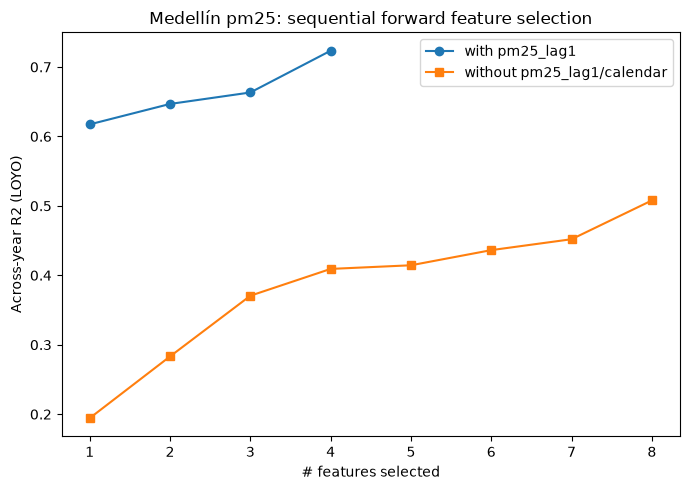

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(1, len(scores_with_lag) + 1), scores_with_lag, marker='o', label='with pm25_lag1')
ax.plot(range(1, len(scores_no_lag) + 1), scores_no_lag, marker='s', label='without pm25_lag1/calendar')
ax.set_xlabel('# features selected')
ax.set_ylabel('Across-year R2 (LOYO)')
ax.set_title('Medellín pm25: sequential forward feature selection')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'sfs_pareto_front.png', dpi=150)
plt.show()


## Save selected feature sets for equation discovery

In [7]:
import json

result = {
    'selected_with_lag': selected_with_lag,
    'scores_with_lag': scores_with_lag,
    'selected_no_lag': selected_no_lag,
    'scores_no_lag': scores_no_lag,
}
out_path = DATA_DIR / "medellin_feature_selection.json"
with open(out_path, 'w') as f:
    json.dump(result, f, indent=2)
print("Saved:", out_path)
print(result)


Saved: /path/to/project/Data/processed/colombia/medellin/medellin_feature_selection.json
{'selected_with_lag': ['pm25_lag1', 'day_of_week', 'hotspots_magdalena_valley', 'radiation_station_lag2'], 'scores_with_lag': [0.6173520790599488, 0.6467710585354274, 0.6632871051360811, 0.7234386485100281], 'selected_no_lag': ['hotspots_sector_NE_lag2', 'secondary_pm_proxy', 'radiation_mean', 'hotspots_magdalena_valley', 'no_lag2', 'w700_lag3', 'hotspots_sector_SE_lag2', 'radiation_station_lag1'], 'scores_no_lag': [0.1943386925536813, 0.28318131337203667, 0.37058950711880323, 0.40920636627504814, 0.4144457539720411, 0.4362629436959975, 0.4519709475620689, 0.5078357664968944]}
